In [1]:
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans


In [2]:
x,y = make_blobs(
    n_samples = 1000,
    n_features = 2,
    centers = 4,
    random_state = 42
)

<Axes: >

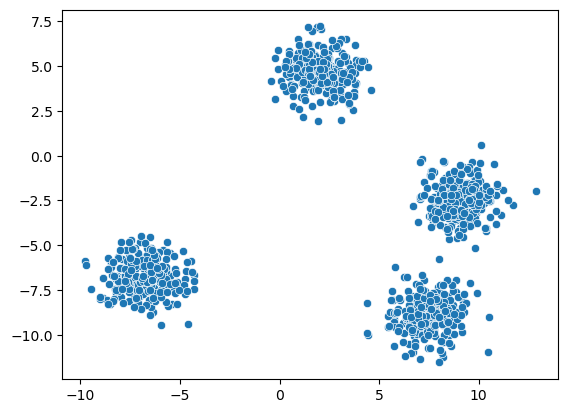

In [3]:
sns.scatterplot(x = x[:, 1], y = x[:,0])

In [4]:
k = 4
kmeans = KMeans(
    n_clusters = k,
    random_state = 40
)
labels = kmeans.fit_predict(x,y)

<Axes: >

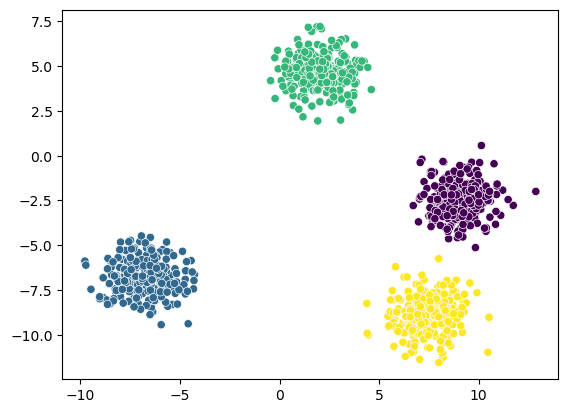

In [5]:
sns.scatterplot(x = x[:, 1], y = x[:,0], c = labels)

# Elbow method

In [6]:
wcss = []
for k in range(1,21):
    kmeans = KMeans(n_clusters = k)
    kmeans.fit_predict(x)
    wcss.append(kmeans.inertia_)

<Axes: >

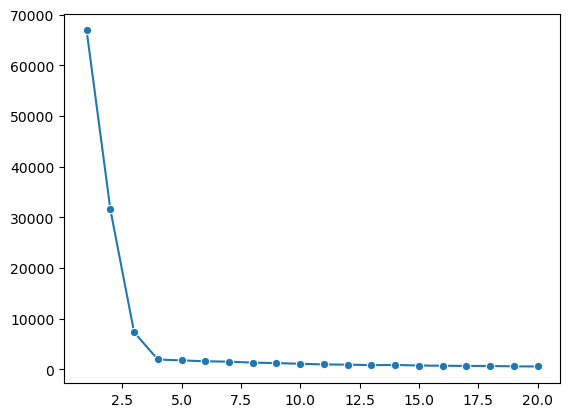

In [8]:
sns.lineplot(x = range(1,21), y = wcss, marker = "o")

In [9]:
pip install kneed

Note: you may need to restart the kernel to use updated packages.


In [11]:
from kneed import KneeLocator
knee = KneeLocator(range(1,21), wcss, curve="convex", direction="decreasing")
print("optimal K = ",knee.knee)

optimal K =  4


In [12]:
from sklearn.metrics import silhouette_score

In [14]:
ss = []
for k in range(2,21):
    kmeans = KMeans(n_clusters = k)
    labels = kmeans.fit_predict(x)
    score = silhouette_score(x,labels)
    ss.append(score)

<Axes: >

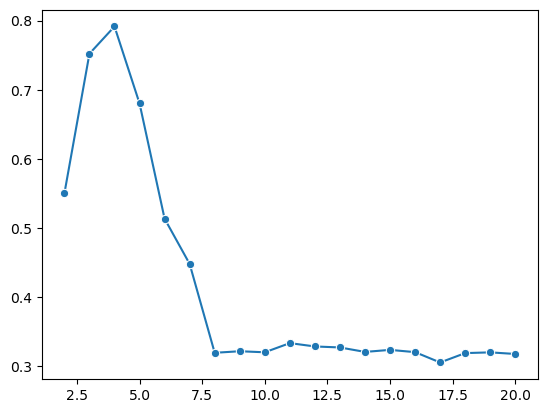

In [17]:
sns.lineplot(x = range(2,21), y = ss, marker = "o")